In [38]:
import numpy as np

def in_circle(coord, k):
    x, y, z = coord
    return x**2 + y**2 + z**2 <= k**2

def in_torus(coord, R, r, offset=(0, 0, 0)):
    x, y, z = coord
    xc, yc, zc = offset
    return (np.sqrt((x-xc)**2 + (y-yc)**2) - R)**2 + (z-zc)**2 <= r**2


def estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=(0, 0, 0), seed=42):
    bbox_size = 2 * (R + r)
    np.random.seed(seed)

    match sample_method:
        case 'uniform':
            samples = np.random.uniform(-bbox_size / 2, bbox_size / 2, size=(n, 3))
        case 'logmap':
            logmap = lambda x: 3.8 * x * (1 - x)
            samples = list(np.random.uniform(0, 1, size=(1, 3)))
            for _ in range(n - 1):
                x, y, z = samples[-1]
                x_new = logmap(x)
                y_new = logmap(y)
                z_new = logmap(z)
                samples.append([x_new, y_new, z_new])
            samples = np.array(samples)
        case _:
            raise ValueError("Unsupported sampling method")
    count = 0
    for sample in samples:
        if in_circle(sample, k) and in_torus(sample, R, r, offset):
            count += 1

    return count / n * bbox_size**3

In [48]:
n = 100_000

# case 1
k = 1
R = .75
r = .4

area_estimate = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

1.8424488099999998


In [34]:
# case 2
k = 1
R = .5
r = .5

area_estimate = estimate_monte_carlo(k, R, r, n, sample_method='uniform')
print(area_estimate)

2.488


In [35]:
k = 1
R = .75
r = .4
offset = (0., 0., 0.1)

area_estimate = estimate_monte_carlo(k, R, r, n, sample_method='uniform', offset=offset)
print(area_estimate)

1.8116662999999997


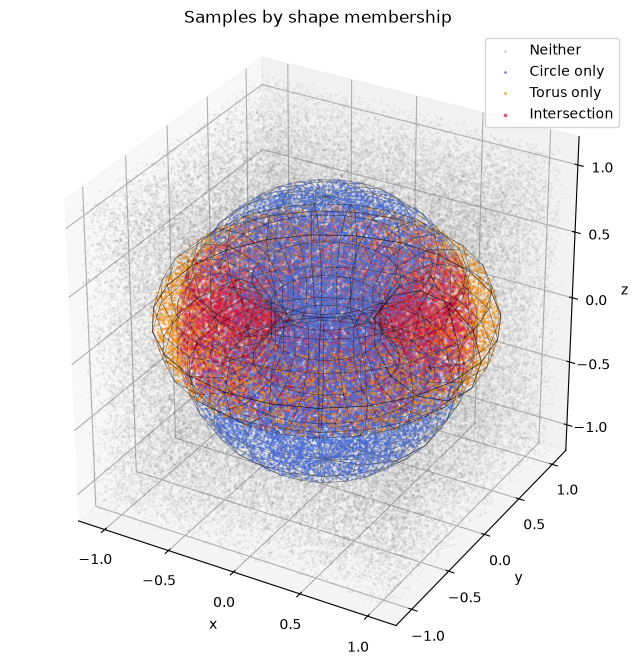

In [58]:
import matplotlib.pyplot as plt

def visualize_system(samples, k, R, r, offset=(0, 0, 0)):
    x0, y0, z0 = offset
    circle = np.sum(samples**2, axis=1) <= k**2
    torus = (np.hypot(samples[:, 0] - x0, samples[:, 1] - y0) - R)**2 + (samples[:, 2] - z0)**2 <= r**2

    fig = plt.figure()
    ax = fig.add_subplot(projection="3d")
    u, v = np.meshgrid(np.linspace(0, 2*np.pi, 20), np.linspace(0, np.pi, 10))
    ax.plot_wireframe(k*np.sin(v)*np.cos(u), k*np.sin(v)*np.sin(u), k*np.cos(v), color="black")
    v = np.linspace(0, 2*np.pi, 10)[:, None]
    ax.plot_wireframe(x0 + (R+r*np.cos(v))*np.cos(u), y0 + (R+r*np.cos(v))*np.sin(u), z0 + r*np.sin(v)*np.ones_like(u), color="black")

    for mask, color, label in [
        (~circle & ~torus, "gray", "Neither"),
        (circle & ~torus, "blue", "Circle only"),
        (~circle & torus, "orange", "Torus only"),
        (circle & torus, "red", "Intersection"),
    ]:
        ax.scatter(*samples[mask].T, c=color, label=label)

    ax.set_box_aspect((1, 1, 1))
    ax.legend()
    plt.show()

np.random.seed(42)
samples = np.random.uniform(-R-r, R+r, (n, 3))
visualize_system(samples, k, R, r, offset)